# 📓 Notebook 2: Tiền Xử Lý & Tách Sọ Não (Skull Stripping)
**Căn cứ tài liệu:** `docs/KHUNG_NOI_DUNG_TONG_QUAT_DO_AN_XLAS.md`  
* **Quy trình chuẩn Bộ môn:** **Bước 2 — Tiền xử lý & Cải thiện chất lượng ảnh (Preprocessing & Skull Stripping)**  
* **Ánh xạ Báo cáo đồ án:** **Mục 4 — Tiền xử lý ảnh**  
* **Học phần:** Xử lý ảnh số (2026–2027) — Khoa CNTT — Trường ĐH Công Thương TP.HCM (HUIT)  
* **Nhóm thực hiện:** Hà Mạnh Trường (2045240326) & Huỳnh Tâm Trí (2045240315) — *Trường phụ trách chính*

---

## 🎯 1. Cơ sở lý thuyết DIP (Gonzalez & Woods Ch. 3, 5 & 9)
1. **Khử nhiễu Rician:** Áp dụng **Bilateral Filter** phi tuyến nhằm lọc nhiễu hạt y tế nhưng bảo toàn độ dốc cường độ tại ranh giới khối u (tránh làm nhòe biên như bộ lọc Gaussian).
2. **Cân bằng tương phản:** Áp dụng **CLAHE** (Contrast Limited Adaptive Histogram Equalization) làm rõ cấu trúc mô mềm chất trắng / chất xám.
3. **Kỹ thuật Tách sọ não kinh điển (Skull Stripping):**
   * *Otsu Thresholding:* Nhị phân hóa tự động phân tách phần đầu khỏi nền đen.
   * *Morphological Opening:* Phép mở với phần tử cấu trúc dạng đĩa (Disk/Ellipse structuring element) cắt đứt các "cầu nối mô" giữa màng não và xương sọ.
   * *Largest Connected Component (LCC):* Trích xuất thành phần liên thông có diện tích lớn nhất (nhu mô não).
   * *Hole Filling:* Lấp đầy lỗ trống não thất bằng phép bù nhị phân và thuật toán FloodFill.
   * *Bitwise-AND:* Nhân mặt nạ não với ảnh gốc để thu được ảnh não sạch sọ hoàn hảo.


In [1]:
%matplotlib inline
import os
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src.preprocessing.filters import apply_bilateral_filter, apply_clahe
from src.preprocessing.skull_strip import extract_brain_mask, strip_skull

print("Module tiền xử lý và tách sọ đã được nạp thành công.")


Module tiền xử lý và tách sọ đã được nạp thành công.


## 🔬 2. Thử Nghiệm Chi Tiết Từng Bước Tách Sọ Trên Ca Mẫu
Phân tích trực quan 6 giai đoạn xử lý từ ảnh MRI gốc đến ảnh sạch sọ:


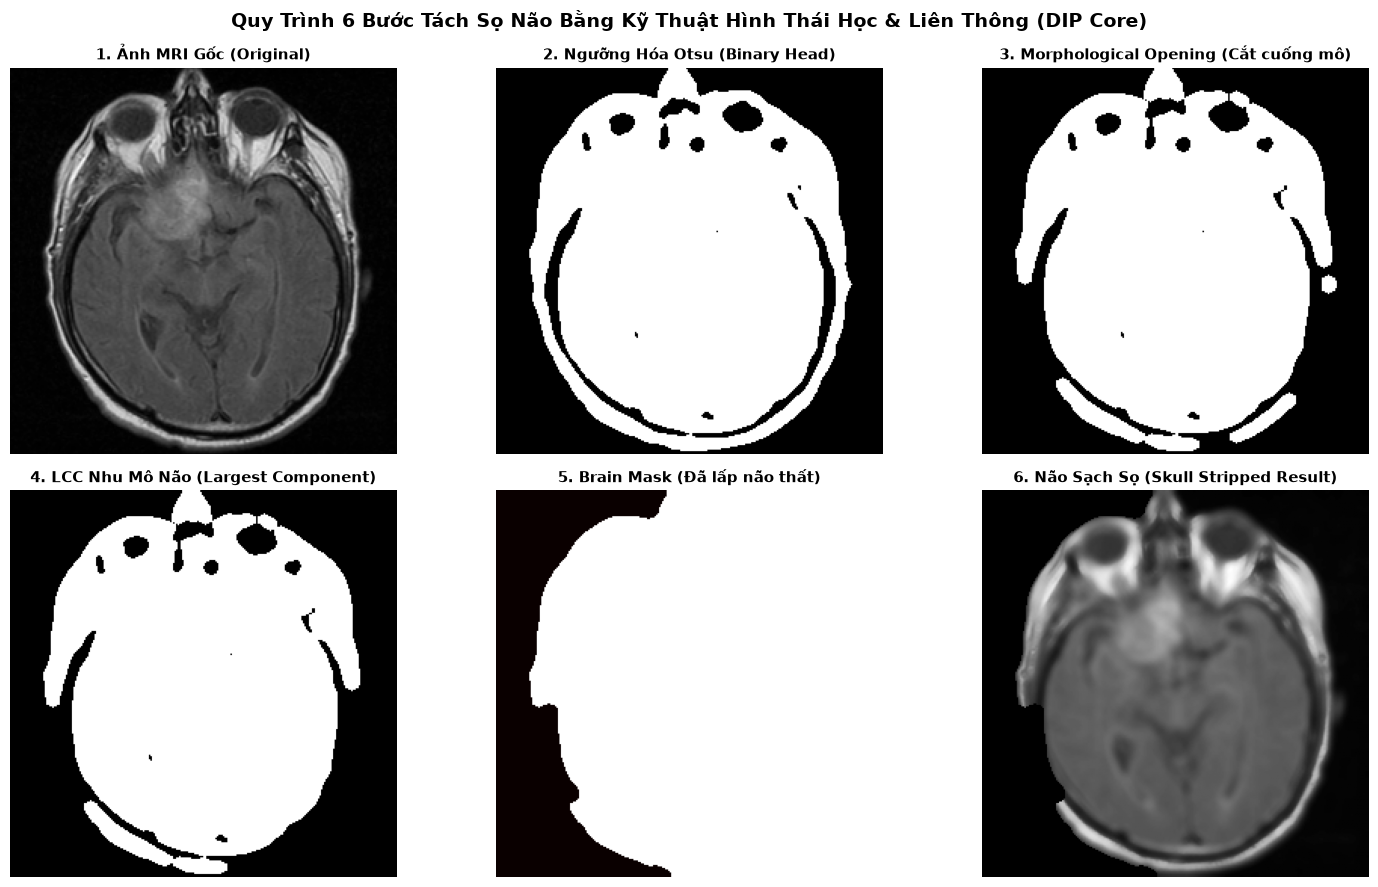

In [2]:
img_path = "../data/sample/images/mri_brain_tumor_01.png"
orig_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# 1. Khử nhiễu Bilateral
denoised = apply_bilateral_filter(orig_img, d=9, sigma_color=75.0, sigma_space=75.0)

# 2-6. Chuỗi 6 bước: Otsu -> Opening -> LCC -> Closing & Hole Filling -> Bitwise-AND
stripped_brain, brain_mask, steps = strip_skull(denoised, return_intermediates=True)

otsu_bin = steps['otsu']
opened = steps['opened']
lcc_mask = steps['lcc']

# Vẽ biểu đồ 6 bước
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
steps = [
    ("1. Ảnh MRI Gốc (Original)", orig_img, 'gray'),
    ("2. Ngưỡng Hóa Otsu (Binary Head)", otsu_bin, 'gray'),
    ("3. Morphological Opening (Cắt cuống mô)", opened, 'gray'),
    ("4. LCC Nhu Mô Não (Largest Component)", lcc_mask, 'gray'),
    ("5. Brain Mask (Đã lấp não thất)", brain_mask, 'hot'),
    ("6. Não Sạch Sọ (Skull Stripped Result)", stripped_brain, 'gray')
]

for i, (title, img_step, cmap) in enumerate(steps):
    r, c = i // 3, i % 3
    axes[r, c].imshow(img_step, cmap=cmap)
    axes[r, c].set_title(title, fontsize=11, fontweight='bold')
    axes[r, c].axis('off')

plt.suptitle("Quy Trình 6 Bước Tách Sọ Não Bằng Kỹ Thuật Hình Thái Học & Liên Thông (DIP Core)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🩺 3. Đánh Giá Khả Năng Tăng Cường Tương Phản CLAHE
So sánh ảnh não sau tách sọ khi có và không áp dụng CLAHE:


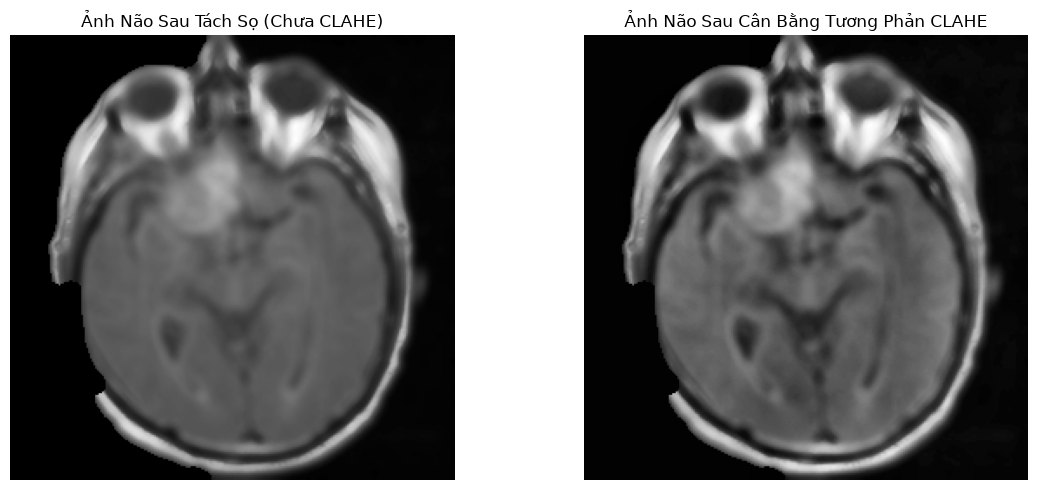

In [3]:
clahe_brain = apply_clahe(stripped_brain, clip_limit=2.0, tile_grid_size=(8, 8))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(stripped_brain, cmap='gray')
axes[0].set_title("Ảnh Não Sau Tách Sọ (Chưa CLAHE)", fontsize=12)
axes[0].axis('off')

axes[1].imshow(clahe_brain, cmap='gray')
axes[1].set_title("Ảnh Não Sau Cân Bằng Tương Phản CLAHE", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 🔍 4. Kiểm Thử Tính Bền Vững Của Tách Sọ Trên 4 Ca Khác Nhau
Chứng minh thuật toán hoạt động ổn định trên nhiều kích thước hộp sọ khác nhau:


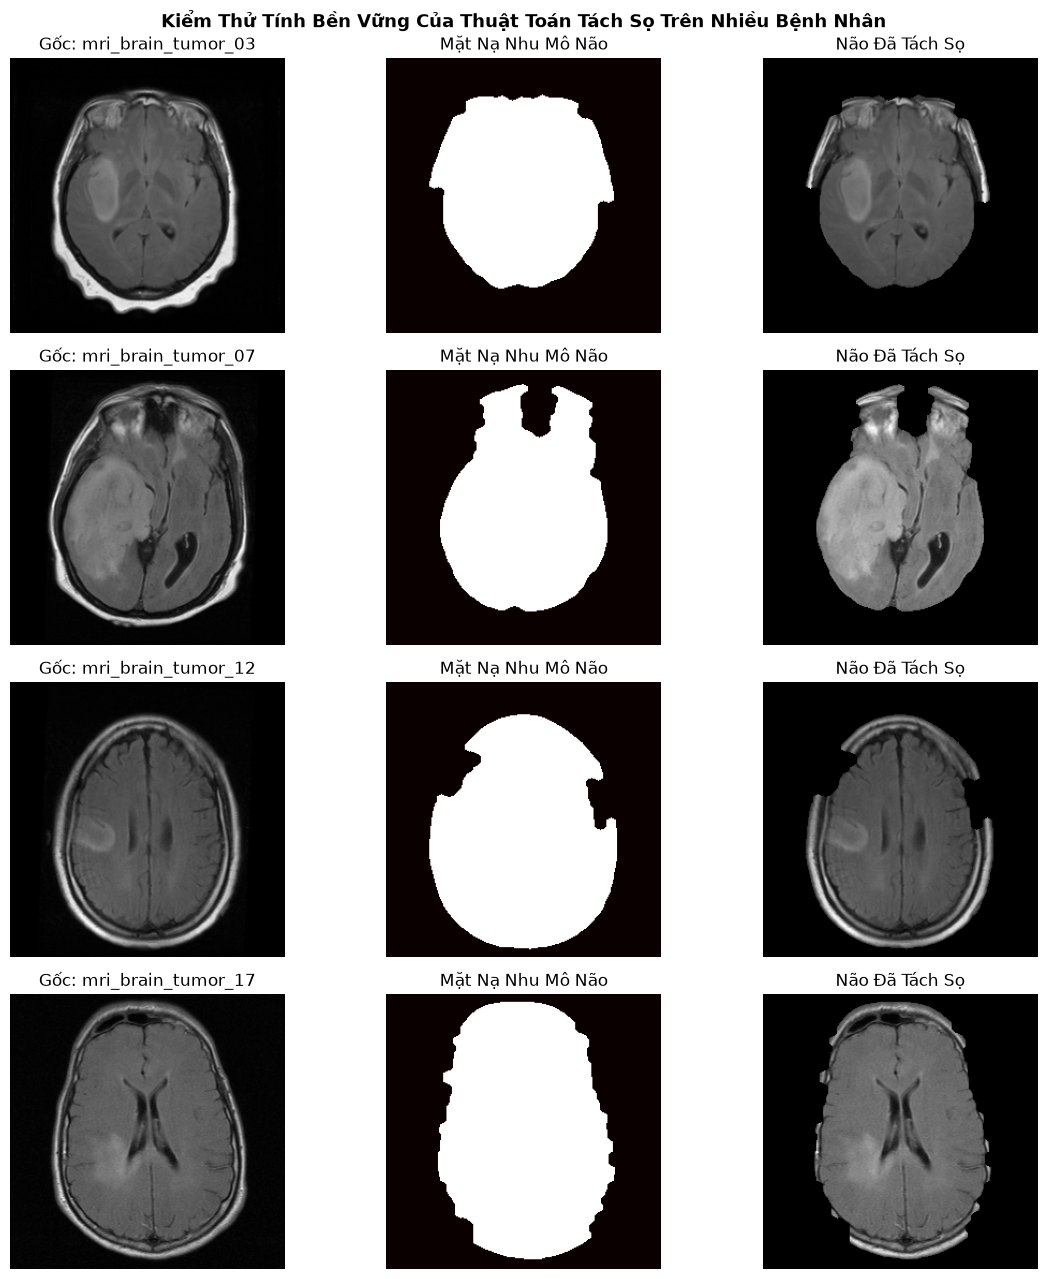

In [4]:
test_cases = ["mri_brain_tumor_03", "mri_brain_tumor_07", "mri_brain_tumor_12", "mri_brain_tumor_17"]

fig, axes = plt.subplots(4, 3, figsize=(12, 13))

for idx, case_id in enumerate(test_cases):
    im_path = f"../data/sample/images/{case_id}.png"
    im = cv2.imread(im_path, cv2.IMREAD_GRAYSCALE)
    b_mask = extract_brain_mask(im)
    res_stripped, _ = strip_skull(im, b_mask)
    
    axes[idx, 0].imshow(im, cmap='gray')
    axes[idx, 0].set_title(f"Gốc: {case_id}")
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(b_mask, cmap='hot')
    axes[idx, 1].set_title("Mặt Nạ Nhu Mô Não")
    axes[idx, 1].axis('off')
    
    axes[idx, 2].imshow(res_stripped, cmap='gray')
    axes[idx, 2].set_title("Não Đã Tách Sọ")
    axes[idx, 2].axis('off')

plt.suptitle("Kiểm Thử Tính Bền Vững Của Thuật Toán Tách Sọ Trên Nhiều Bệnh Nhân", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
